In [12]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd
import np as np
import matplotlib.pyplot as plt

dataset= pd.read_csv("Mall_Customers.csv")

# New Section

extraction des varibles independantes

In [14]:
x=dataset.iloc[:,[3,4]]
x

,Annual Income (k$),Spending Score (1-100)
0,15,39.0
1,15,81.0
2,16,6.0
3,16,77.0
4,17,40.0
...,...,...
195,120,16.0
196,120,79.0
197,126,28.0
198,126,74.0


deplicated number

In [15]:
y=x.duplicated().sum()
y

4

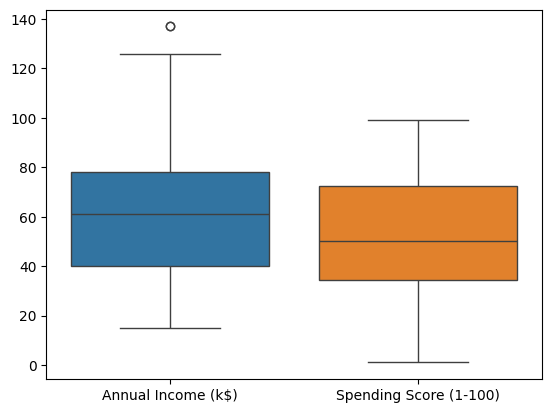

NameError: name 'np' is not defined

In [19]:
import seaborn as sns
x.duplicated().sum()
sns.boxplot(data=x, orient="v")
plt.show()

index = np.where(x> 130)
print(index)

In [ ]:
import numpy as np
index = np.where(x['Annual Income (k$)'] > 130)
index
x = x.drop(index[0])

y = x.isnull().sum()
y


In [ ]:
x = x.fillna({"Spending Score (1-100)" : int(x["Spending Score (1-100)"].mean())})

mise a l'echelle

In [ ]:
x = x.values
plt.hist(x[:,0])
plt.hist(x[:,1], alpha=0.8)
plt.show()

In [ ]:
plt.rcParams["figure.figsize"]=(10,10)
plt.scatter(x[: ,0], x[:,1], s = 50, c="red")
plt.title("Customers")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score(1-100)")
plt.show()

In [ ]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters= 2, init= "k-means++" , random_state = 0)
kmeans.fit(x)

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


KMeans(n_clusters=2, random_state=0)

In [ ]:
y_kmeans = kmeans.labels_
y_kmeans

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
      dtype=int32)

In [ ]:
center_kmeans = kmeans.cluster_centers_
center_kmeans

array([[36.6741573 , 50.05617978],
       [78.2293578 , 49.76146789]])

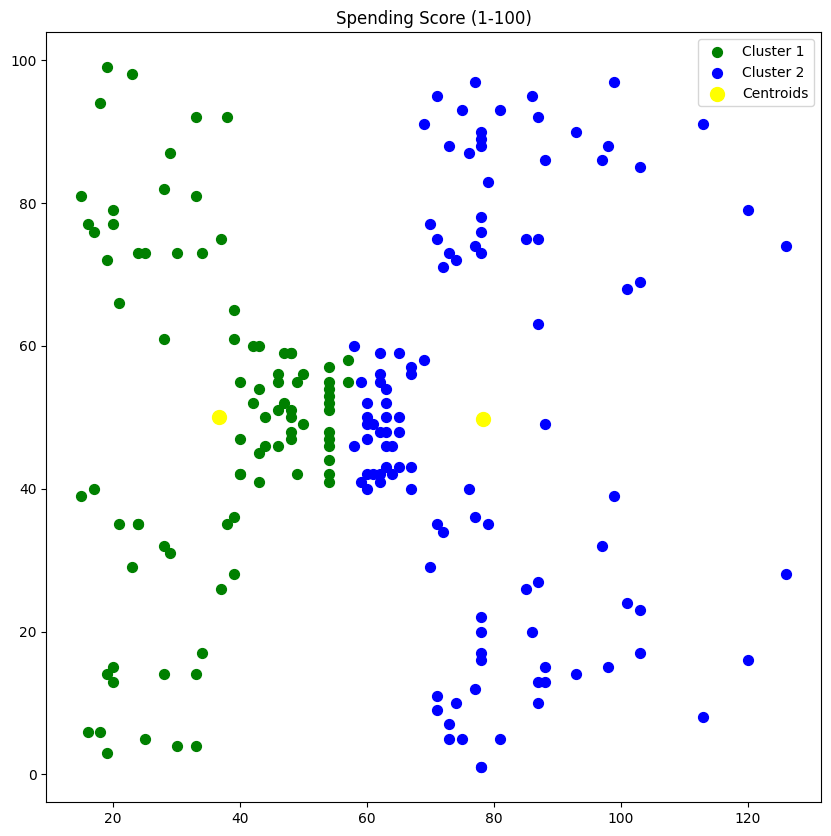

In [ ]:
plt.scatter(x[y_kmeans == 0 , 0], x[y_kmeans == 0 ,1],
            s = 50, c = "green"  , label = "Cluster 1")
plt.scatter(x[y_kmeans == 1 , 0], x[y_kmeans == 1 ,1],
            s = 50, c = "blue"  , label = "Cluster 2")
plt.scatter(center_kmeans[: , 0], center_kmeans[: , 1],
            s = 100, c = "yellow"  , label = "Centroids")
plt.title("Clusters of customers")
plt.title("Annual Income (k$)")
plt.title("Spending Score (1-100)")
plt.legend()
plt.show()